# 02 · Ordinal DR grader: train, TTA evaluation, external validation, screening tool

**Kaggle settings:** Accelerator **GPU T4 x2**, Internet **On** (to download timm weights).
Input: the output of `01_preprocess`. Attach it via *Add Input → Notebooks*, or as a dataset made from that output.

| stage | data |
|---|---|
| train | EyePACS-2015 train + APTOS-2019 (deduplicated), minus val |
| val | 10 % patient-grouped holdout; used for checkpoint selection and threshold tuning |
| internal test | EyePACS-2015 test (~53k, labels released after the competition) |
| **external** | Messidor-2 with adjudicated grades (different country, camera and grading protocol); never used for tuning |

**Method**
* Backbone: ViT-B/16 at **512 px** (1024 tokens) by default, with pos-embeddings interpolated from 384. Any timm model works, e.g. an EfficientNet as the CNN baseline.
* **Ordinal head:** 4 logits, one per cumulative probability P(grade > k), trained with BCE (Frank & Hall / CORAL-style).
  The continuous score Σσ(logitₖ) is the expected grade. Grade cut-offs are tuned on val to maximise QWK.
* **Imbalance:** sampling weight ∝ class_count^-α, with α = 0.5 (square-root rebalancing). Fully balanced sampling over-predicts the rare grades.
  The threshold tuning on val, which keeps the natural class mix, then recalibrates the decision point.
* **Label noise:** ordinal label smoothing, plus the APTOS duplicate-conflict removal from notebook 01. Evaluation uses the *adjudicated* Messidor-2 labels.
* **TTA:** identity + h-flip + v-flip + 180° rotation. The TTA spread is also used as an uncertainty signal that sends an image to a human grader.

In [1]:
import functools, glob, json, os, time, zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, cohen_kappa_score, confusion_matrix, roc_auc_score

SMOKE = bool(os.environ.get('DR_SMOKE'))  # tiny CPU run that only exercises the code path
DATA = Path(os.environ.get('DR_DATA') or Path(sorted(glob.glob('/kaggle/input/**/labels.csv', recursive=True))[0]).parent)
WORK = Path(os.environ.get('DR_WORK', '/kaggle/working'))

MODEL = 'resnet50.a1_in1k'  # CNN: 'resnet50.a1_in1k' with LR = 1e-4 (Huang et al. 2021 reference)
IMG = 512            # input resolution. Microaneurysms are ~2-4 px here; avoid going below 448.
PREPROC = 'ben'       # 'ben' (Graham 2015) | 'clahe' | 'none'
EPOCHS, BS, LR = 10, 16, 1e-4  # LR applies to the backbone; the head gets 10x
SAMPLE_ALPHA = 0.5    # sampling weight ∝ count^-alpha: 0 = natural distribution, 1 = fully balanced
SMOOTH = 0.05         # ordinal label smoothing (robustness to label noise)
N_TTA = 4
GRAD_CKPT = False     # True if CUDA OOM (slower, much less memory)
TIME_BUDGET_H = 9.0   # stop training early so evaluation still fits in Kaggle's 12 h session
CKPT = '/kaggle/input/notebooks/abhi0204/diabetic-retinopathy-train-and-eval-2-cnn/model.pt'           # path to an existing model.pt to skip training (re-run eval/screening without spending GPU hours)
SENS_TARGET = 0.90    # screening referral cut-off: referable-DR sensitivity it must reach on val
WORKERS = os.cpu_count()
if SMOKE:
    MODEL, IMG, EPOCHS, BS, WORKERS = 'vit_tiny_patch16_224', 64, 1, 4, 2

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEV == 'cuda'
WORK.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
torch.backends.cudnn.benchmark = True  # fixed input size: let cuDNN pick the fastest conv kernels
print(DATA, DEV, torch.cuda.device_count(), 'GPU(s)')

/kaggle/input/notebooks/abhi0204/diabetic-retinopathy-preprocessing cuda 2 GPU(s)


In [2]:
df = pd.read_csv(DATA / 'labels.csv')
df = df[df.keep & df.grade.notna()].astype({'grade': int})
splits = {s: d.reset_index(drop=True) for s, d in df.groupby('split')}
print(pd.crosstab(df.split, df.grade, margins=True))

grade         0     1      2     3     4    All
split                                          
external   1017   270    347    75    35   1744
test      39529  3762   7860  1214  1206  53571
train     24864  2509   5590   907   877  34747
val        2739   270    623   134    95   3861
All       68149  6811  14420  2330  2213  93923


In [3]:
@functools.cache
def _shard(name, pid):  # one handle per worker process
    p = DATA / f'{name}.zip'
    return zipfile.ZipFile(p) if p.exists() else DATA / name  # Kaggle may auto-extract zips into datasets


def load(shard, stem):
    s = _shard(shard, os.getpid())
    data = s.read(f'{stem}.jpg') if isinstance(s, zipfile.ZipFile) else (s / f'{stem}.jpg').read_bytes()
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def enhance(img, how=PREPROC):
    s = img.shape[0]
    if how == 'ben':  # subtract local average colour: normalises illumination and camera differences, keeps lesions
        img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), s / 30), -4, 128)
    elif how == 'clahe':
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        lab[..., 0] = cv2.createCLAHE(2.0, (8, 8)).apply(lab[..., 0])
        img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    mask = np.zeros((s, s, 1), np.uint8)
    cv2.circle(mask, (s // 2, s // 2), int(s * 0.45), 1, -1)  # clip the rim, where the blur leaves a bright ring
    return np.where(mask, img, 128 if how == 'ben' else 0).astype(np.uint8)


def augment(img, rng):
    s = img.shape[0]
    if rng.random() < 0.5:
        img = img[:, ::-1]
    m = cv2.getRotationMatrix2D((s / 2, s / 2), rng.uniform(0, 360), rng.uniform(0.95, 1.1))
    img = cv2.warpAffine(np.ascontiguousarray(img), m, (s, s))
    return np.clip(img * rng.uniform(0.8, 1.2) + rng.uniform(-20, 20), 0, 255).astype(np.uint8)  # exposure jitter


class DS(torch.utils.data.Dataset):
    def __init__(self, d, train):
        self.d, self.train = d, train

    def __len__(self):
        return len(self.d)

    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = cv2.resize(load(r.shard, r.stem), (IMG, IMG), interpolation=cv2.INTER_AREA)
        if self.train:
            img = augment(img, np.random.default_rng())
        return torch.from_numpy(enhance(img)).permute(2, 0, 1), torch.tensor(r.grade, dtype=torch.float32)


def loader(d, train):
    sampler = None
    if train:
        w = d.grade.map(d.grade.value_counts() ** -SAMPLE_ALPHA).to_numpy(copy=True)
        sampler = torch.utils.data.WeightedRandomSampler(w, len(d))
    return torch.utils.data.DataLoader(DS(d, train), BS if train else 2 * BS, sampler=sampler, num_workers=WORKERS,
                                       pin_memory=AMP, drop_last=train, persistent_workers=WORKERS > 0)

In [4]:
def make_model():
    kw = dict(pretrained=not SMOKE, num_classes=4)
    try:
        m = timm.create_model(MODEL, img_size=IMG, **kw)  # ViT/Swin: resample position embeddings to IMG
    except TypeError:
        m = timm.create_model(MODEL, **kw)  # CNNs accept any size
    m.set_grad_checkpointing(GRAD_CKPT)
    return m.to(DEV, memory_format=torch.channels_last)  # NHWC: fast fp16 tensor-core convs (matters for CNNs)


model = make_model()
MEAN = torch.tensor(model.pretrained_cfg['mean'], device=DEV).view(1, 3, 1, 1) * 255
STD = torch.tensor(model.pretrained_cfg['std'], device=DEV).view(1, 3, 1, 1) * 255
net = nn.DataParallel(model) if torch.cuda.device_count() > 1 else model


def norm(x):
    return ((x.to(DEV, non_blocking=True).float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)


def ordinal_targets(y):  # grade -> [y>0, y>1, y>2, y>3], smoothed towards 0.5
    return (y[:, None] > torch.arange(4, device=y.device)).float() * (1 - SMOOTH) + SMOOTH / 2


def expected_grade(logits):  # E[grade] = sum_k P(grade > k), continuous in [0, 4]
    return torch.sigmoid(logits.float()).sum(1)


def qwk(y, p):
    return cohen_kappa_score(y, p, weights='quadratic')


def to_grade(s, thr=(0.5, 1.5, 2.5, 3.5)):
    return np.digitize(s, thr)


@torch.no_grad()
def predict(d, tta=N_TTA):
    """Returns (mean, std) of the expected grade over TTA views."""
    net.eval()
    out = []
    for x, _ in loader(d, train=False):
        x = norm(x)
        views = [x, x.flip(3), x.flip(2), x.flip((2, 3))][:tta]
        with torch.autocast(DEV, dtype=torch.float16, enabled=AMP):
            out.append(torch.stack([expected_grade(net(v)) for v in views], 1).cpu())
    s = torch.cat(out).numpy()
    return s.mean(1), s.std(1)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

## Train

In [5]:
def train():
    head = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head}
    body = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{'params': body, 'lr': LR}, {'params': head, 'lr': LR * 10}], weight_decay=0.05)
    dl = loader(splits['train'], train=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, [LR, LR * 10], total_steps=EPOCHS * len(dl), pct_start=0.1)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, t0, hist = -1.0, time.time(), []
    for ep in range(EPOCHS):
        net.train()
        te, tot, wait, tw = time.time(), 0.0, 0.0, time.time()
        for i, (x, y) in enumerate(dl):
            wait += time.time() - tw  # time blocked on the DataLoader
            with torch.autocast(DEV, dtype=torch.float16, enabled=AMP):
                logits = net(norm(x))
            loss = F.binary_cross_entropy_with_logits(logits.float(), ordinal_targets(y.to(DEV)))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item()  # also syncs the GPU, so `wait` below is real data-loading time
            if i % 200 == 0:
                gpu = torch.cuda.max_memory_allocated() / 2**30 if AMP else 0
                print(f'ep {ep} it {i}/{len(dl)} loss {tot / (i + 1):.4f} {(i + 1) * BS / (time.time() - te):.1f} img/s | '
                      f'data-wait {wait / (time.time() - te):.0%} gpu-mem {gpu:.1f}G host-ram {psutil.virtual_memory().percent:.0f}%')
            tw = time.time()
        s, _ = predict(splits['val'], tta=1)
        k = qwk(splits['val'].grade, to_grade(s))
        hist.append({'epoch': ep, 'loss': tot / len(dl), 'val_qwk': k, 'min': (time.time() - t0) / 60})
        print(hist[-1])
        if k > best:
            best = k
            torch.save(model.state_dict(), WORK / 'model.pt')
        if (time.time() - t0) * (ep + 2) / (ep + 1) > TIME_BUDGET_H * 3600:
            print('time budget reached, stopping')
            break
    pd.DataFrame(hist).to_csv(WORK / 'history.csv', index=False)


if CKPT is None:
    train()
model.load_state_dict(torch.load(CKPT or WORK / 'model.pt', map_location=DEV))

<All keys matched successfully>

## Evaluation
Grade cut-offs and the uncertainty threshold are fitted on **val only** and then frozen for the internal test and the external Messidor-2 set.
Every metric gets a 95 % bootstrap CI. Referable DR (rDR) means grade ≥ 2 (moderate NPDR or worse). Vision-threatening DR (VTDR) means grade ≥ 3.
Two operating points: the QWK-optimal grade cut-offs (for grading), and a **screening** cut-off on the score set to `SENS_TARGET` rDR sensitivity on val (`@screen`, for referral).

thresholds [0.811 1.472 2.281 3.269] uncertainty cut-off 0.23 screening cut-off 0.611

===== val  (n=3861) =====
qwk                  0.834  [0.817, 0.849]
acc                  0.792  [0.780, 0.805]
rdr_sens             0.737  [0.706, 0.765]
rdr_spec             0.974  [0.969, 0.980]
rdr_auc              0.947  [0.937, 0.957]
rdr_sens@screen      0.900  [0.879, 0.922]
rdr_spec@screen      0.850  [0.836, 0.862]
vtdr_sens            0.773  [0.720, 0.819]
vtdr_spec            0.959  [0.952, 0.964]
vtdr_auc             0.964  [0.950, 0.974]
patient_rdr_sens@screen 0.923
patient_rdr_spec@screen 0.780
uncertain_frac       0.050
qwk_confident_only   0.851
              precision    recall  f1-score   support

      0 none      0.910     0.941     0.925      2739
      1 mild      0.231     0.278     0.252       270
  2 moderate      0.706     0.429     0.533       623
    3 severe      0.347     0.687     0.461       134
       4 PDR      0.774     0.505     0.611        95

    accuracy     

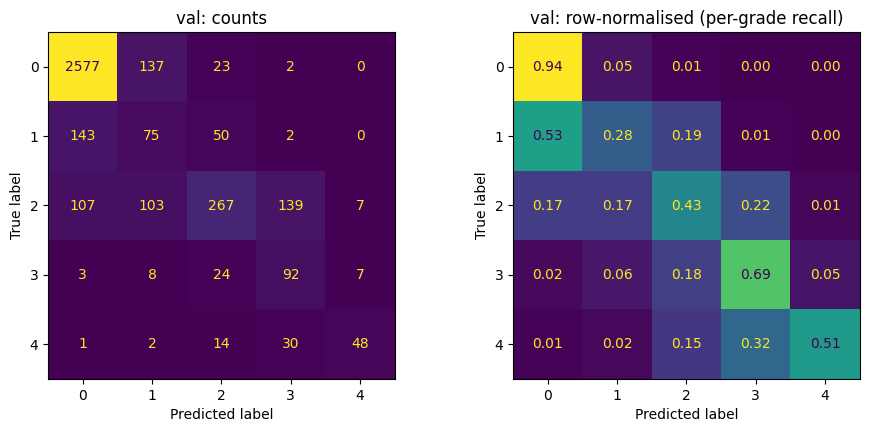

val QWK on aptos: 0.893  (n=351)
val QWK on eyepacs: 0.819  (n=3510)

===== test  (n=53571) =====
qwk                  0.804  [0.799, 0.809]
acc                  0.802  [0.799, 0.805]
rdr_sens             0.673  [0.664, 0.681]
rdr_spec             0.981  [0.980, 0.982]
rdr_auc              0.938  [0.934, 0.940]
rdr_sens@screen      0.879  [0.873, 0.885]
rdr_spec@screen      0.861  [0.858, 0.864]
vtdr_sens            0.782  [0.767, 0.799]
vtdr_spec            0.970  [0.969, 0.972]
vtdr_auc             0.971  [0.968, 0.974]
patient_rdr_sens@screen 0.904
patient_rdr_spec@screen 0.791
uncertain_frac       0.051
qwk_confident_only   0.819
              precision    recall  f1-score   support

      0 none      0.903     0.944     0.923     39529
      1 mild      0.230     0.275     0.250      3762
  2 moderate      0.744     0.408     0.527      7860
    3 severe      0.308     0.694     0.426      1214
       4 PDR      0.805     0.455     0.582      1206

    accuracy                    

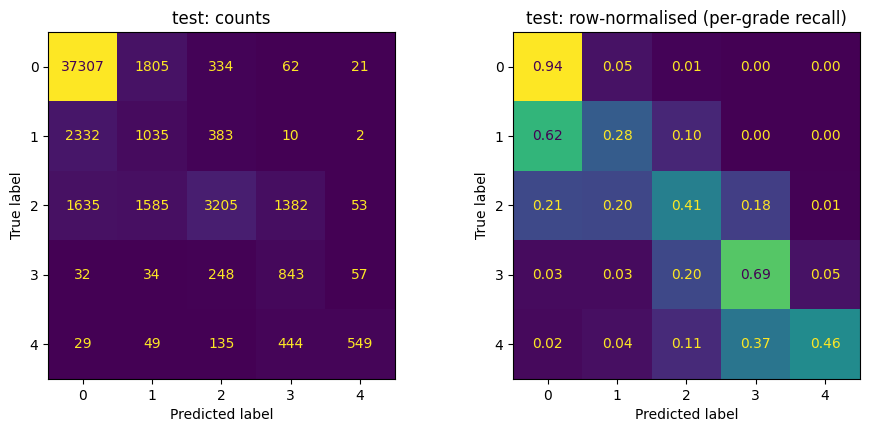


===== external  (n=1744) =====
qwk                  0.819  [0.796, 0.839]
acc                  0.707  [0.685, 0.728]
rdr_sens             0.834  [0.800, 0.864]
rdr_spec             0.933  [0.920, 0.946]
rdr_auc              0.958  [0.947, 0.968]
rdr_sens@screen      0.980  [0.966, 0.992]
rdr_spec@screen      0.608  [0.582, 0.635]
vtdr_sens            0.909  [0.851, 0.959]
vtdr_spec            0.958  [0.949, 0.968]
vtdr_auc             0.989  [0.983, 0.994]
patient_rdr_sens@screen 0.980
patient_rdr_spec@screen 0.608
uncertain_frac       0.099
qwk_confident_only   0.854
              precision    recall  f1-score   support

      0 none      0.873     0.813     0.842      1017
      1 mild      0.345     0.422     0.380       270
  2 moderate      0.706     0.608     0.653       347
    3 severe      0.437     0.787     0.562        75
       4 PDR      0.667     0.629     0.647        35

    accuracy                          0.707      1744
   macro avg      0.606     0.652     0.617 

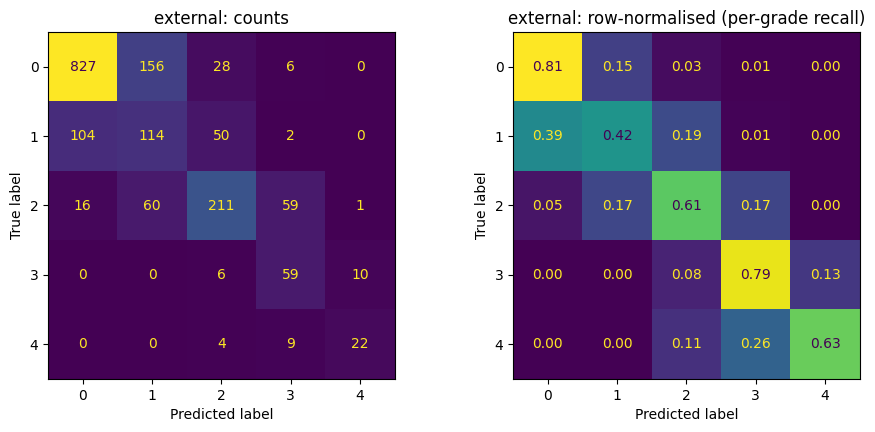

In [6]:
def fit_thresholds(y, s):  # coordinate ascent on QWK (the APTOS "OptimizedRounder" idea)
    thr = [0.5, 1.5, 2.5, 3.5]
    for _ in range(3):
        for k in range(4):
            lo, hi = (thr[k - 1] if k else 0.0), (thr[k + 1] if k < 3 else 4.0)
            thr[k] = max(np.linspace(lo, hi, 41)[1:-1], key=lambda t: qwk(y, to_grade(s, thr[:k] + [t] + thr[k + 1:])))
    return thr


def binary(y, p, s, cut):
    yt, pt = y >= cut, p >= cut
    auc = roc_auc_score(yt, s) if 0 < yt.sum() < len(yt) else np.nan
    return pt[yt].mean() if yt.any() else np.nan, (~pt[~yt]).mean() if (~yt).any() else np.nan, auc


def metrics(y, p, s):
    r = binary(y, p, s, 2)
    v = binary(y, p, s, 3)
    o = binary(y, (s >= RDR_T) * 2, s, 2)  # screening operating point
    return {'qwk': qwk(y, p), 'acc': (y == p).mean(), 'rdr_sens': r[0], 'rdr_spec': r[1], 'rdr_auc': r[2],
            'rdr_sens@screen': o[0], 'rdr_spec@screen': o[1], 'vtdr_sens': v[0], 'vtdr_spec': v[1], 'vtdr_auc': v[2]}


def report(name, d, s, sd, thr, unc):
    y, p = d.grade.values, to_grade(s, thr)
    rng = np.random.default_rng(0)
    boot = pd.DataFrame([metrics(y[i], p[i], s[i]) for i in rng.integers(0, len(y), (500, len(y)))])
    m = metrics(y, p, s)
    res = {k: {'value': v, 'ci95': list(boot[k].quantile([0.025, 0.975]))} for k, v in m.items()}
    # Screening decisions are per patient: refer if either eye passes the screening cut-off
    pat = pd.DataFrame({'pt': d.patient, 'y': y, 'ref': s >= RDR_T}).groupby('pt').max()
    res['patient_rdr_sens@screen'] = float(pat.ref[pat.y >= 2].mean())
    res['patient_rdr_spec@screen'] = float((~pat.ref[pat.y < 2]).mean())
    flagged = sd > unc
    res['uncertain_frac'] = float(flagged.mean())
    res['qwk_confident_only'] = qwk(y[~flagged], p[~flagged]) if (~flagged).sum() > 1 else np.nan

    print(f'\n===== {name}  (n={len(y)}) =====')
    for k, v in res.items():
        print(f'{k:20s}', f"{v['value']:.3f}  [{v['ci95'][0]:.3f}, {v['ci95'][1]:.3f}]" if isinstance(v, dict) else f'{v:.3f}')
    print(classification_report(y, p, labels=range(5), digits=3, zero_division=0,
                                target_names=['0 none', '1 mild', '2 moderate', '3 severe', '4 PDR']))
    print('true vs predicted grade distribution (bias check):')
    print(pd.DataFrame({'true': np.bincount(y, minlength=5), 'pred': np.bincount(p, minlength=5)}).T)
    cm = confusion_matrix(y, p, labels=range(5))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay(cm).plot(ax=ax[0], colorbar=False, values_format='d')
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True).clip(1)).plot(ax=ax[1], colorbar=False, values_format='.2f')
    ax[0].set_title(f'{name}: counts')
    ax[1].set_title(f'{name}: row-normalised (per-grade recall)')
    fig.savefig(WORK / f'cm_{name}.png', dpi=120, bbox_inches='tight')
    plt.show()
    d.assign(score=s, score_sd=sd, pred=p).to_csv(WORK / f'pred_{name}.csv', index=False)
    return res


val_s, val_sd = predict(splits['val'])
THR = fit_thresholds(splits['val'].grade.values, val_s)
UNC = float(np.quantile(val_sd, 0.95))  # top 5 % most TTA-unstable images go to human review
RDR_T = float(np.quantile(val_s[splits['val'].grade.values >= 2], 1 - SENS_TARGET, method='lower'))  # referral cut-off; 'lower' guarantees >= SENS_TARGET
print('thresholds', np.round(THR, 3), 'uncertainty cut-off', round(UNC, 3), 'screening cut-off', round(RDR_T, 3))

results = {'config': dict(model=MODEL, img=IMG, preproc=PREPROC, epochs=EPOCHS, alpha=SAMPLE_ALPHA, smooth=SMOOTH,
                          tta=N_TTA, thresholds=THR, uncertainty_sd=UNC, screening_threshold=RDR_T)}
results['val'] = report('val', splits['val'], val_s, val_sd, THR, UNC)
for src, d in splits['val'].groupby('dataset'):  # bias check across sources
    print(f'val QWK on {src}: {qwk(d.grade, to_grade(val_s[d.index], THR)):.3f}  (n={len(d)})')
for name in ('test', 'external'):
    if name in splits:
        s, sd = predict(splits[name])
        results[name] = report(name, splits[name], s, sd, THR, UNC)
json.dump(results, open(WORK / 'metrics.json', 'w'), indent=1, default=float)

## Screening tool
`screen(paths, patients)` takes **raw** fundus photographs, as a screening camp would capture them, and returns one row per image.
Each row has the grade, the continuous score, a TTA-uncertainty flag and a recommendation. With `patients=` it also returns the patient-level decision, taken from the worse eye.
It reuses the trained network and the frozen val thresholds.
The crop below is copied from `01_preprocess.crop_fundus`; keep the two in sync.

In [7]:
from PIL import Image

GRADE_NAMES = ['No DR', 'Mild NPDR', 'Moderate NPDR', 'Severe NPDR', 'Proliferative DR']


def crop_fundus(img, size=768):  # same as 01_preprocess.crop_fundus
    mask = img.max(2) > 15
    rows, cols = np.flatnonzero(mask.mean(1) > 0.02), np.flatnonzero(mask.mean(0) > 0.02)
    if len(rows) < 32 or len(cols) < 32:
        return None
    img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    h, w = img.shape[:2]
    d = max(h, w)
    sq = np.zeros((d, d, 3), np.uint8)
    sq[(d - h) // 2:(d - h) // 2 + h, (d - w) // 2:(d - w) // 2 + w] = img
    return cv2.resize(sq, (size, size), interpolation=cv2.INTER_AREA)


def recommend(grade, refer, uncertain):
    if grade is None:
        return 'Ungradable: retake photo'
    if uncertain:
        return 'Send to human grader'
    if grade >= 3:
        return 'Urgent referral'
    if refer:  # screening cut-off (SENS_TARGET sensitivity), deliberately more sensitive than the grade cut-offs
        return 'Refer to ophthalmologist'
    return 'Rescreen in 6-12 months' if grade == 1 else 'Rescreen in 12 months'


@torch.no_grad()
def screen(paths, patients=None):
    net.eval()
    rows = []
    for path in paths:
        im = Image.open(path)
        im.draft('RGB', (768, 768))
        img = crop_fundus(np.asarray(im.convert('RGB')))
        if img is None:
            rows.append({'file': str(path), 'grade': None, 'recommendation': recommend(None, False, False)})
            continue
        img = enhance(cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA))
        x = norm(torch.from_numpy(img).permute(2, 0, 1)[None])
        with torch.autocast(DEV, dtype=torch.float16, enabled=AMP):
            s = torch.stack([expected_grade(net(v)) for v in [x, x.flip(3), x.flip(2), x.flip((2, 3))][:N_TTA]]).cpu().numpy()
        g = int(to_grade(s.mean(), THR))
        unc, ref = bool(s.std() > UNC), bool(s.mean() >= RDR_T)
        rows.append({'file': str(path), 'grade': g, 'grade_name': GRADE_NAMES[g], 'score': round(float(s.mean()), 3),
                     'tta_sd': round(float(s.std()), 3), 'referable': ref, 'uncertain': unc,
                     'recommendation': recommend(g, ref, unc)})
    out = pd.DataFrame(rows)
    if patients is not None:
        out['patient'] = list(patients)
        g = out.groupby('patient')
        worst = g.grade.transform('max')
        refer = g.referable.transform('max').fillna(False)
        unc = g.uncertain.transform('max').fillna(False)
        out['patient_recommendation'] = [recommend(None if pd.isna(w) else int(w), r, u) for w, r, u in zip(worst, refer, unc)]
    return out


# Demo on a few raw Messidor-2 photographs (any folder of fundus images works)
raw = sorted(glob.glob(str(Path(os.environ.get('DR_INPUT', '/kaggle/input')) / '**/messidor-2/images/*'), recursive=True))[:8]
if raw:
    print(screen(raw).to_string())

## Clinical limitations
Fill the bracketed numbers in from `metrics.json` after the run.

1. **Research prototype, not a medical device.** It is not validated prospectively and has no regulatory clearance (FDA/CE/CDSCO). For comparison, IDx-DR, the first FDA-cleared autonomous DR system, was approved on a prospective trial with pre-registered endpoints.
   The output is a triage aid that prioritises human grading. It is not a diagnosis.
2. **Label quality.** EyePACS grades come from a single grader per image and are known to be noisy (Krause et al. 2018). Mild DR (grade 1) is the least reliable class for both humans and models.
   Expect the lowest per-grade recall there; see the confusion matrices.
3. **Domain shift.** Training data comes from US primary-care clinics (EyePACS) and India (APTOS, Aravind). Messidor-2 is from France.
   Performance on Messidor-2 [QWK …, rDR sens/spec …] is the best available estimate for an unseen site, but a new camera, population or operator can still degrade results.
   Before deployment, validate on local images from the actual camp cameras, which are often handheld and non-mydriatic.
4. **No image-quality model.** The tool only rejects photos in which no fundus disc can be found.
   Blurred, dark or poorly centred images still get a grade. Real deployments reject a large share of field images as ungradable (Beede et al. 2020), so add a gradeability check and a human fallback.
5. **Grades only DR severity.** It does not detect diabetic macular oedema, which can be vision-threatening at any DR grade.
   It also misses glaucoma, AMD, vein occlusions and other incidental findings, so a "No DR" result is not a normal eye exam.
6. **Single 45° field vs. ETDRS 7-field.** Peripheral lesions outside the photographed field are invisible to the model.
7. **Operating point.** Grade cut-offs were tuned for QWK on the internal val set. A screening programme should instead fix the rDR operating point to a target sensitivity (e.g. ≥ 85-90 %), accept the specificity that follows, and re-check it on local data.
8. **Uncertainty flag.** The TTA disagreement flag catches some unstable predictions, but it is not calibrated. Confidently wrong predictions still happen.
9. **Fairness is unverified.** None of the datasets ship age, sex or ethnicity metadata, so subgroup performance cannot be audited. Per-grade recall and per-source QWK are the only bias checks performed.